# Palier 2 · Le perceptron multicouche (MLP)

## 1. Imports, graine et données

In [1]:
# À mettre AVANT d'importer TensorFlow : désactive les optimisations oneDNN,
# qui changent l'ordre des calculs et donnent des résultats un peu différents à chaque lancement
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)

print("Python    :", sys.version.split()[0])
print("NumPy     :", np.__version__)
print("TensorFlow:", tf.__version__)
print("Keras     :", keras.__version__)

Python    : 3.12.7
NumPy     : 2.5.5
TensorFlow: 2.21.0
Keras     : 3.15.1


In [2]:
# Les mêmes jeux que dans le notebook 1 (même découpage, même graine)
sys.path.append("..")
from src.data import load_data

x_train, y_train, x_val, y_val, x_test, y_test = load_data(seed=SEED)

# Un MLP prend un vecteur en entrée : 28 x 28 -> 784
X_train = x_train.reshape(len(x_train), 784)
X_val = x_val.reshape(len(x_val), 784)
X_test = x_test.reshape(len(x_test), 784)  # gardé pour la section 9 seulement

print("X_train :", X_train.shape, "/ X_val :", X_val.shape, "/ X_test :", X_test.shape)
print("Pixels entre", X_train.min(), "et", X_train.max())

X_train : (54000, 784) / X_val : (6000, 784) / X_test : (10000, 784)
Pixels entre 0.0 et 1.0


J'utilise les mêmes jeux que dans le notebook 1 : 54 000 images pour l'entraînement et 6 000 pour la validation, avec les pixels entre 0 et 1. J'aplatis chaque image en un vecteur de 784 pixels, parce qu'une couche `Dense` ne sait pas lire une image 2D. Je prépare aussi `X_test`, mais il ne servira qu'une seule fois, à la section 9.

*Reproductibilité :* en plus de la graine, je désactive oneDNN (`TF_ENABLE_ONEDNN_OPTS=0`, avant d'importer TensorFlow), et `run()` active `enable_op_determinism()`. Sans ça, j'obtenais 2,02 %, puis 2,10 %, puis 2,13 % d'erreur en relançant exactement le même code. Maintenant, deux relances donnent les mêmes chiffres au centième près (seule la durée varie).

## 2. Fonctions utiles : plot_history et run

J'ai mis les fonctions dans `src/utils.py` pour pouvoir les réutiliser dans le notebook du CNN :

- `build_mlp(hidden, dropout, batchnorm)` construit un MLP : entrée de 784 pixels → couches cachées ReLU → 10 sorties softmax ;
- `plot_history(history, titre)` trace la loss et l'erreur (1 − accuracy), pour l'entraînement et pour la validation, côte à côte ;
- `run(...)` fait un essai complet. Elle fixe la graine, **construit un modèle neuf**, compile, chronomètre l'entraînement, trace les courbes et ajoute une ligne au tableau `resultats`.

`run` reçoit une **fonction** qui crée le modèle (`lambda: build_mlp(...)`), et pas un modèle déjà construit. Comme ça, la graine est fixée *avant* l'initialisation des poids : chaque essai part des mêmes poids, et je ne continue jamais par erreur l'entraînement d'un ancien modèle.

In [3]:
from src.utils import build_mlp, plot_history, run

donnees = (X_train, y_train, X_val, y_val)   # jamais le test pendant les essais
resultats = []                               # une ligne par essai, affichée en tableau à la section 8

## 3. MLP de référence

In [4]:
# On construit une fois le modèle juste pour lire son résumé
keras.utils.set_random_seed(SEED)
build_mlp(hidden=(256,)).summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

**Calcul du nombre de paramètres à la main** (un poids par connexion, plus un biais par neurone) :

| couche | calcul | paramètres |
|---|---|---|
| Dense 784 → 256 | 784 × 256 + 256 | 200 960 |
| Dense 256 → 10 | 256 × 10 + 10 | 2 570 |
| **total** | | **203 530** |

C'est exactement ce qu'affiche `summary()` (203 530). Presque tout est dans la première couche (99 %), parce que chaque pixel est relié à chacun des 256 neurones.

Epoch 1/20


422/422 - 2s - 6ms/step - accuracy: 0.9117 - loss: 0.3142 - val_accuracy: 0.9505 - val_loss: 0.1809


Epoch 2/20


422/422 - 2s - 4ms/step - accuracy: 0.9611 - loss: 0.1357 - val_accuracy: 0.9650 - val_loss: 0.1315


Epoch 3/20


422/422 - 2s - 4ms/step - accuracy: 0.9733 - loss: 0.0936 - val_accuracy: 0.9697 - val_loss: 0.1101


... (30 outputs left out)

Epoch 19/20


422/422 - 2s - 4ms/step - accuracy: 0.9993 - loss: 0.0038 - val_accuracy: 0.9808 - val_loss: 0.0991


Epoch 20/20


422/422 - 2s - 4ms/step - accuracy: 0.9997 - loss: 0.0024 - val_accuracy: 0.9797 - val_loss: 0.1016


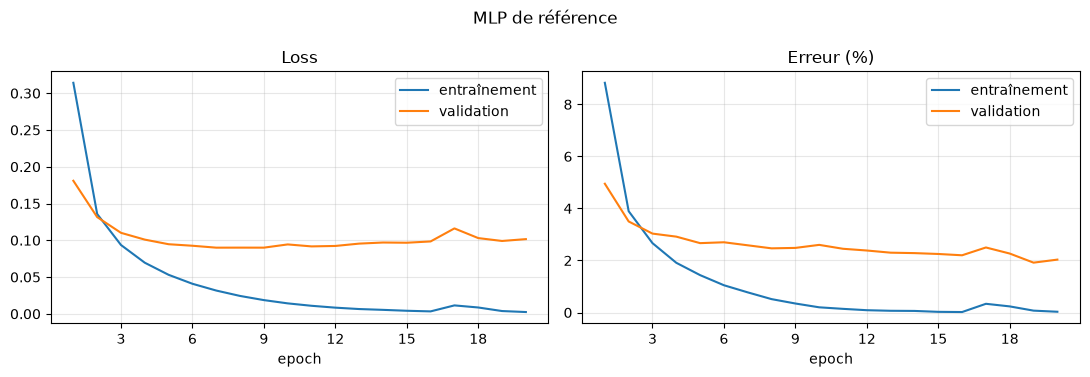

In [5]:
# Référence : 784 -> 256 (ReLU) -> 10 (softmax), Adam lr = 0,001, batch 128, 20 epochs
model_ref, hist_ref = run(
    "MLP de référence",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="référence : 256 neurones, Adam 1e-3, batch 128",
    save="../images/p2_ref_courbes.png",
)

In [6]:
pd.DataFrame(resultats)

,nom,changement,parametres,epochs,erreur_val_%,meilleure_erreur_val_%,epoch_meilleure,duree_s
0,MLP de référence,"référence : 256 neurones, Adam 1e-3, batch 128",203530,20,2.03,1.92,19,33.5


**Pourquoi 422 itérations par epoch ?** Une itération, c'est un paquet (batch) de 128 images : le modèle calcule l'erreur sur ce paquet, puis corrige ses poids une fois. Pour voir les 54 000 images une fois (= une epoch), il faut 54 000 / 128 = 421,875 paquets. On fait donc 421 paquets complets, plus un dernier paquet de 54 000 − 421 × 128 = **112 images**, soit **422 itérations**. C'est bien le `422/422` affiché par Keras à chaque epoch.

**Ce que je lis sur les courbes** (`images/p2_ref_courbes.png`) :

- L'erreur de **validation** baisse vite : 4,95 % après la 1re epoch, environ 2,6 % à l'epoch 7. Ensuite, elle descend lentement : **1,92 % au mieux (epoch 19)** et **2,03 % à la fin (epoch 20)**.
- Pendant ce temps, l'erreur d'**entraînement** tombe presque à 0 % (accuracy de 99,97 %) : le modèle a quasiment appris les 54 000 images par cœur.
- La **loss de validation** est au plus bas entre les epochs 7 et 9 (0,090), puis elle remonte (0,102 à la fin), alors que la loss d'entraînement continue de baisser. **C'est un début de surapprentissage** : le modèle devient trop sûr de lui sur les images de validation qu'il classe mal, même si le nombre d'erreurs ne remonte pas encore. L'écart entre train et validation s'agrandit. Je traiterai ça à la section 6 (dropout, early stopping).
- Il y a un pic à l'epoch 17 : la loss d'entraînement remonte d'un coup (de 0,003 à 0,011), et l'erreur de validation aussi. C'est un « à-coup » d'Adam quand la loss est déjà presque nulle, et il se corrige dès les epochs suivantes.
- L'entraînement prend environ 30 s sur le CPU (environ 1,5 s par epoch).

**Comparaison avec la baseline :** le MLP de référence fait **2,03 %** d'erreur sur la validation à la fin (1,92 % au mieux), contre **3,42 %** pour la forêt aléatoire du notebook 1. La baseline est battue ✅ (environ 40 % d'erreurs en moins).

## 4. Comparaison de configurations (une variable à la fois)

Je garde la référence du jour 4 (784 → 256 → 10, Adam 0,001, batch 128, 20 epochs) et je change **une seule chose à la fois**. Comme ça, si l'erreur change, je sais d'où ça vient. Tous les essais ont la même graine, les mêmes données et 20 epochs. Le jeu de test n'est jamais utilisé.

Epoch 1/20


422/422 - 4s - 10ms/step - accuracy: 0.9207 - loss: 0.2783 - val_accuracy: 0.9547 - val_loss: 0.1605


Epoch 2/20


422/422 - 3s - 8ms/step - accuracy: 0.9674 - loss: 0.1139 - val_accuracy: 0.9675 - val_loss: 0.1149


Epoch 3/20


422/422 - 3s - 8ms/step - accuracy: 0.9792 - loss: 0.0736 - val_accuracy: 0.9737 - val_loss: 0.0966


... (30 outputs left out)

Epoch 19/20


422/422 - 3s - 8ms/step - accuracy: 0.9998 - loss: 0.0012 - val_accuracy: 0.9807 - val_loss: 0.1027


Epoch 20/20


422/422 - 3s - 8ms/step - accuracy: 0.9993 - loss: 0.0029 - val_accuracy: 0.9820 - val_loss: 0.1009


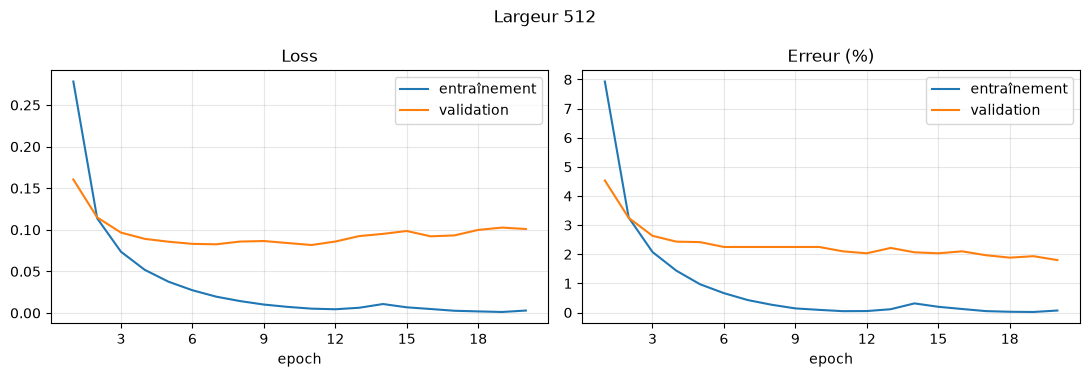

In [7]:
# Essai 1 : LARGEUR -> 512 neurones dans la couche cachée (tout le reste = référence)
model_512, hist_512 = run(
    "Largeur 512",
    creer_modele=lambda: build_mlp(hidden=(512,)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="largeur : 512 neurones au lieu de 256",
    save="../images/p2_largeur_512.png",
)

Epoch 1/20


422/422 - 3s - 6ms/step - accuracy: 0.9186 - loss: 0.2831 - val_accuracy: 0.9568 - val_loss: 0.1568


Epoch 2/20


422/422 - 2s - 4ms/step - accuracy: 0.9674 - loss: 0.1090 - val_accuracy: 0.9638 - val_loss: 0.1257


Epoch 3/20


422/422 - 2s - 4ms/step - accuracy: 0.9794 - loss: 0.0704 - val_accuracy: 0.9695 - val_loss: 0.1025


... (30 outputs left out)

Epoch 19/20


422/422 - 2s - 4ms/step - accuracy: 0.9973 - loss: 0.0082 - val_accuracy: 0.9757 - val_loss: 0.1434


Epoch 20/20


422/422 - 2s - 4ms/step - accuracy: 0.9974 - loss: 0.0079 - val_accuracy: 0.9775 - val_loss: 0.1327


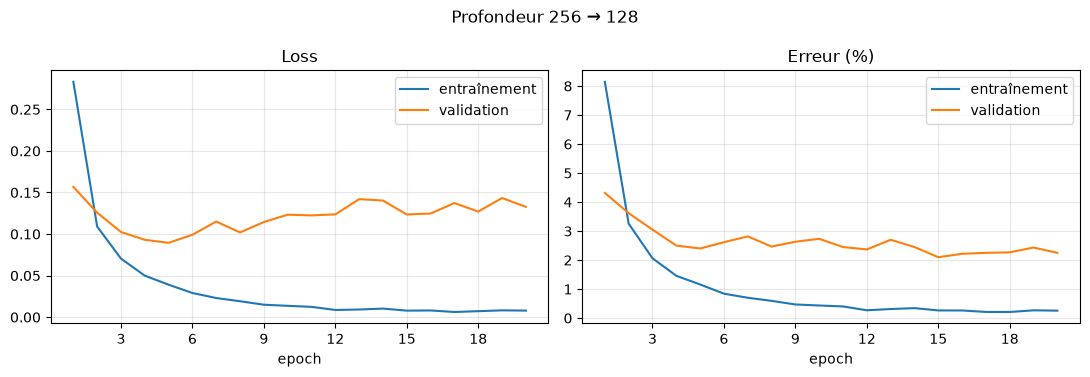

In [8]:
# Essai 2 : PROFONDEUR -> deux couches cachées 256 puis 128
model_deux_couches, hist_deux_couches = run(
    "Profondeur 256 → 128",
    creer_modele=lambda: build_mlp(hidden=(256, 128)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="profondeur : 2 couches cachées (256 → 128)",
    save="../images/p2_profondeur_256_128.png",
)

Epoch 1/20


1688/1688 - 6s - 3ms/step - accuracy: 0.9318 - loss: 0.2317 - val_accuracy: 0.9567 - val_loss: 0.1437


Epoch 2/20


1688/1688 - 5s - 3ms/step - accuracy: 0.9713 - loss: 0.0951 - val_accuracy: 0.9682 - val_loss: 0.1088


Epoch 3/20


1688/1688 - 5s - 3ms/step - accuracy: 0.9823 - loss: 0.0598 - val_accuracy: 0.9745 - val_loss: 0.0943


... (30 outputs left out)

Epoch 19/20


1688/1688 - 5s - 3ms/step - accuracy: 0.9977 - loss: 0.0062 - val_accuracy: 0.9775 - val_loss: 0.1372


Epoch 20/20


1688/1688 - 5s - 3ms/step - accuracy: 0.9985 - loss: 0.0042 - val_accuracy: 0.9763 - val_loss: 0.1565


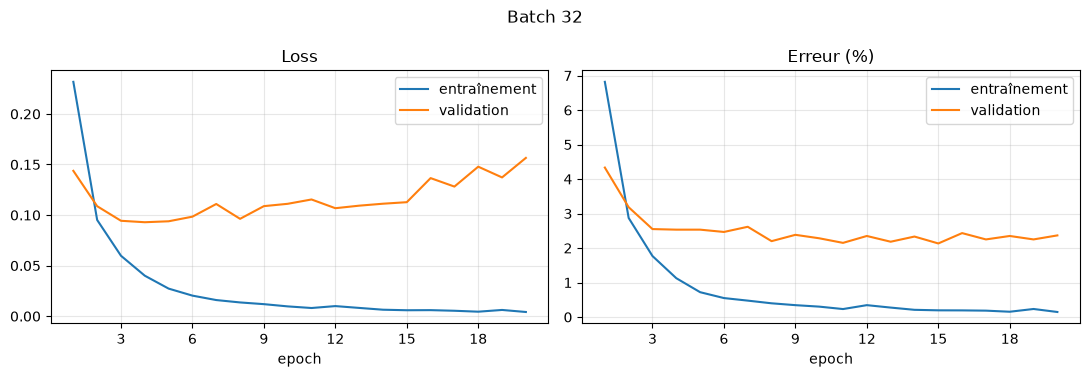

In [9]:
# Essai 3 : BATCH SIZE -> 32 (54 000 / 32 = 1 687,5 -> 1 688 itérations par epoch)
model_b32, hist_b32 = run(
    "Batch 32",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=32,
    epochs=20,
    changement="batch size : 32 au lieu de 128",
    save="../images/p2_batch_32.png",
)

Epoch 1/20


106/106 - 1s - 14ms/step - accuracy: 0.8634 - loss: 0.5100 - val_accuracy: 0.9283 - val_loss: 0.2630


Epoch 2/20


106/106 - 1s - 8ms/step - accuracy: 0.9392 - loss: 0.2158 - val_accuracy: 0.9460 - val_loss: 0.1962


Epoch 3/20


106/106 - 1s - 8ms/step - accuracy: 0.9551 - loss: 0.1600 - val_accuracy: 0.9547 - val_loss: 0.1601


... (30 outputs left out)

Epoch 19/20


106/106 - 1s - 8ms/step - accuracy: 0.9981 - loss: 0.0153 - val_accuracy: 0.9768 - val_loss: 0.0865


Epoch 20/20


106/106 - 1s - 8ms/step - accuracy: 0.9985 - loss: 0.0137 - val_accuracy: 0.9763 - val_loss: 0.0872


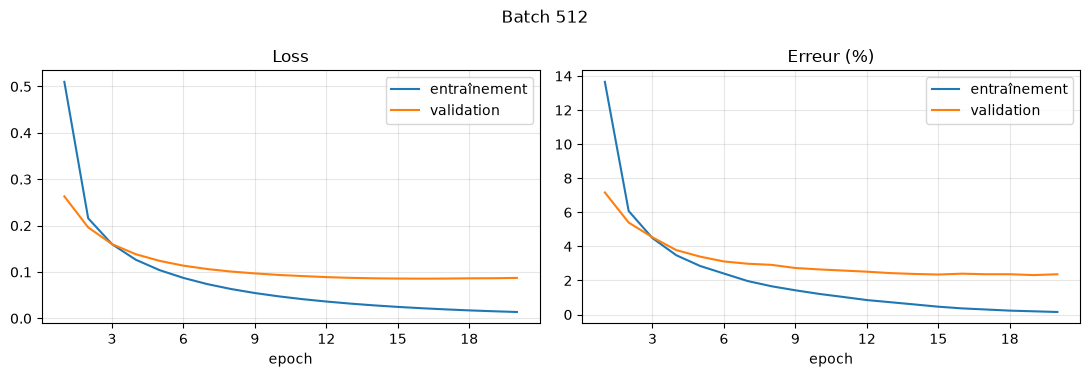

In [10]:
# Essai 4 : BATCH SIZE -> 512 (54 000 / 512 = 105,5 -> 106 itérations par epoch)
model_b512, hist_b512 = run(
    "Batch 512",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=512,
    epochs=20,
    changement="batch size : 512 au lieu de 128",
    save="../images/p2_batch_512.png",
)

Epoch 1/20


422/422 - 2s - 5ms/step - accuracy: 0.7281 - loss: 1.1796 - val_accuracy: 0.8438 - val_loss: 0.6858


Epoch 2/20


422/422 - 1s - 4ms/step - accuracy: 0.8635 - loss: 0.5639 - val_accuracy: 0.8750 - val_loss: 0.4919


Epoch 3/20


422/422 - 1s - 3ms/step - accuracy: 0.8839 - loss: 0.4476 - val_accuracy: 0.8888 - val_loss: 0.4204


... (30 outputs left out)

Epoch 19/20


422/422 - 1s - 3ms/step - accuracy: 0.9363 - loss: 0.2285 - val_accuracy: 0.9325 - val_loss: 0.2430


Epoch 20/20


422/422 - 1s - 3ms/step - accuracy: 0.9374 - loss: 0.2237 - val_accuracy: 0.9348 - val_loss: 0.2389


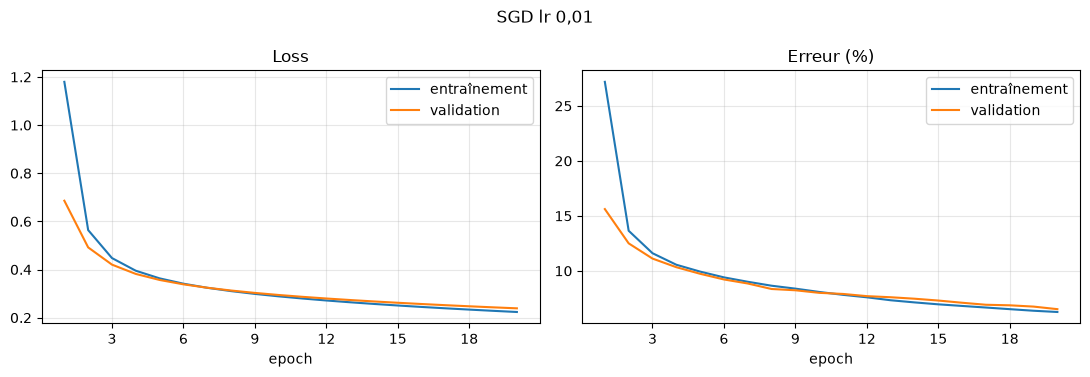

In [11]:
# Essai 5 : OPTIMISEUR -> SGD simple avec lr = 0,01 (une valeur classique pour SGD)
model_sgd, hist_sgd = run(
    "SGD lr 0,01",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="optimiseur : SGD (lr 0,01) au lieu d'Adam (lr 0,001)",
    save="../images/p2_sgd.png",
)

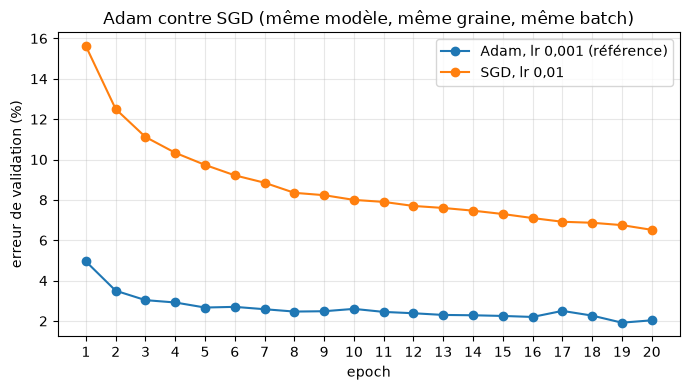

epoch  1 : Adam 4.95 %  |  SGD 15.62 %
epoch  5 : Adam 2.67 %  |  SGD 9.73 %
epoch 10 : Adam 2.60 %  |  SGD 8.00 %
epoch 20 : Adam 2.03 %  |  SGD 6.52 %


In [12]:
# Adam (référence) contre SGD : erreur de validation à chaque epoch, sur le même graphique
def erreur_val(hist):
    return 100 * (1 - np.array(hist.history["val_accuracy"]))

epochs = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, erreur_val(hist_ref), marker="o", label="Adam, lr 0,001 (référence)")
ax.plot(epochs, erreur_val(hist_sgd), marker="o", label="SGD, lr 0,01")
ax.set_xlabel("epoch")
ax.set_ylabel("erreur de validation (%)")
ax.set_xticks(epochs)
ax.set_title("Adam contre SGD (même modèle, même graine, même batch)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../images/p2_adam_vs_sgd.png", dpi=100, bbox_inches="tight")
plt.show()

for e in [1, 5, 10, 20]:
    print(f"epoch {e:2d} : Adam {erreur_val(hist_ref)[e - 1]:.2f} %  |  SGD {erreur_val(hist_sgd)[e - 1]:.2f} %")

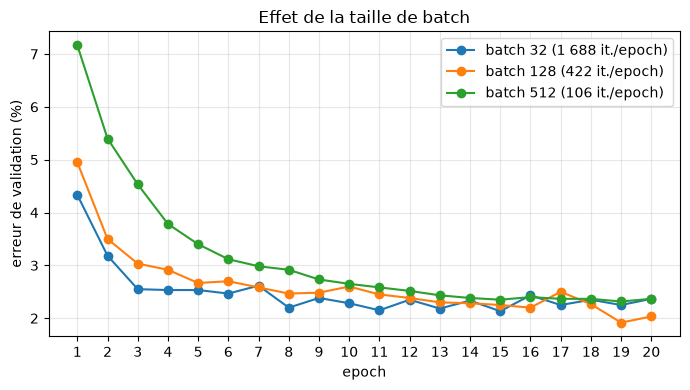

In [13]:
# Les trois tailles de batch sur le même graphique
fig, ax = plt.subplots(figsize=(7, 4))
for hist, nom in [(hist_b32, "batch 32 (1 688 it./epoch)"),
                  (hist_ref, "batch 128 (422 it./epoch)"),
                  (hist_b512, "batch 512 (106 it./epoch)")]:
    ax.plot(epochs, erreur_val(hist), marker="o", label=nom)
ax.set_xlabel("epoch")
ax.set_ylabel("erreur de validation (%)")
ax.set_xticks(epochs)
ax.set_title("Effet de la taille de batch")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../images/p2_batch_sizes.png", dpi=100, bbox_inches="tight")
plt.show()

In [14]:
# Tableau des essais, du meilleur au moins bon (erreur de validation à la dernière epoch)
tableau = pd.DataFrame(resultats).sort_values("erreur_val_%").reset_index(drop=True)
tableau

,nom,changement,parametres,epochs,erreur_val_%,meilleure_erreur_val_%,epoch_meilleure,duree_s
0,Largeur 512,largeur : 512 neurones au lieu de 256,407050,20,1.80,1.80,20,67.3
1,MLP de référence,"référence : 256 neurones, Adam 1e-3, batch 128",203530,20,2.03,1.92,19,33.5
2,Profondeur 256 → 128,profondeur : 2 couches cachées (256 → 128),235146,20,2.25,2.10,15,35.6
3,Batch 32,batch size : 32 au lieu de 128,203530,20,2.37,2.13,15,103.7
4,Batch 512,batch size : 512 au lieu de 128,203530,20,2.37,2.32,19,17.0
5,"SGD lr 0,01","optimiseur : SGD (lr 0,01) au lieu d'Adam (lr ...",203530,20,6.52,6.52,20,28.1


**Ce que je retiens du tableau** (erreur de validation à l'epoch 20 ; sur 6 000 images, 0,1 % = 6 images) :

- **Ce qui a aidé :** la **largeur 512** fait 1,80 % d'erreur contre 2,03 % pour la référence, soit 14 images de moins mal classées. Mais c'est avec 2 fois plus de paramètres (407 050) et 2 fois plus de temps (environ 75 s contre 30 à 35 s).
- **Ce qui n'a rien changé (ou un peu moins bien) :** la **2e couche cachée** (2,25 %), le **batch 32** (2,37 %) et le **batch 512** (2,37 %). Les écarts sont de 0,2 à 0,3 point, soit 13 à 20 images. Avec une seule graine, je ne peux pas affirmer que c'est vraiment moins bien : ça reste du même ordre que la référence.
- **Ce qui a coûté du temps :** le **batch 32** fait 1 688 itérations par epoch au lieu de 422, et il prend environ 110 à 130 s, 3 à 4 fois la référence, pour un résultat qui n'est pas meilleur. À l'inverse, le **batch 512** (106 itérations par epoch) est le plus rapide (environ 17 à 20 s), mais il démarre plus lentement (7,2 % d'erreur après l'epoch 1, contre 5,0 % pour la référence).
- **Ce qui a clairement fait pire :** **SGD** (lr 0,01) fait 6,52 % d'erreur après 20 epochs, plus de 3 fois l'erreur d'Adam, pour une durée du même ordre. Sa courbe descend encore : il n'a pas fini d'apprendre.

➡️ Pour la suite, je garde la référence (256 neurones, Adam, batch 128) comme base : c'est le meilleur compromis entre erreur et temps. Je retiens que la largeur 512 est la piste la plus prometteuse.

## 5. Learning rate trop bas / trop élevé

Ici, je fais exprès de mal régler le **learning rate** (la taille des pas de correction) pour voir à quoi ça ressemble. Je reprends la référence (256 neurones, Adam, batch 128, 20 epochs) et je ne change que le learning rate : **1e-5** (100 fois plus petit), **0,1** (100 fois plus grand) et **1** (1 000 fois plus grand). La courbe à 1e-3, c'est la référence de la section 3.

Epoch 1/20


422/422 - 3s - 6ms/step - accuracy: 0.3734 - loss: 2.0456 - val_accuracy: 0.6400 - val_loss: 1.7317


Epoch 2/20


422/422 - 2s - 4ms/step - accuracy: 0.7297 - loss: 1.4639 - val_accuracy: 0.7733 - val_loss: 1.2452


Epoch 3/20


422/422 - 2s - 4ms/step - accuracy: 0.7979 - loss: 1.0727 - val_accuracy: 0.8127 - val_loss: 0.9463


... (30 outputs left out)

Epoch 19/20


422/422 - 2s - 4ms/step - accuracy: 0.9176 - loss: 0.3059 - val_accuracy: 0.9178 - val_loss: 0.3136


Epoch 20/20


422/422 - 2s - 4ms/step - accuracy: 0.9194 - loss: 0.2989 - val_accuracy: 0.9185 - val_loss: 0.3074


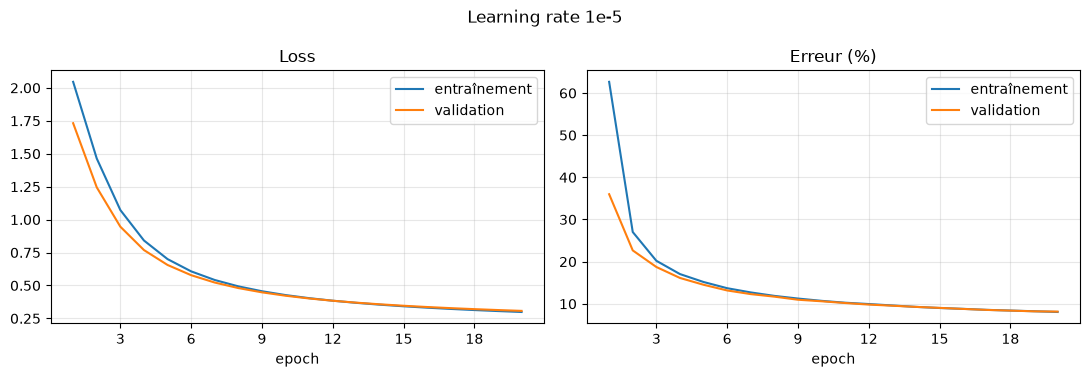

In [15]:
# Learning rate TROP BAS : 100 fois plus petit que la référence
model_lr_1e5, hist_lr_1e5 = run(
    "Learning rate 1e-5",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="learning rate : 1e-5 au lieu de 1e-3 (trop bas)",
    save="../images/p2_lr_1e-5.png",
)

Epoch 1/20


422/422 - 2s - 5ms/step - accuracy: 0.8399 - loss: 0.9132 - val_accuracy: 0.8910 - val_loss: 0.4894


Epoch 2/20


422/422 - 1s - 4ms/step - accuracy: 0.8840 - loss: 0.5241 - val_accuracy: 0.8857 - val_loss: 0.5768


Epoch 3/20


422/422 - 1s - 4ms/step - accuracy: 0.8802 - loss: 0.5346 - val_accuracy: 0.8718 - val_loss: 0.6101


... (30 outputs left out)

Epoch 19/20


422/422 - 2s - 4ms/step - accuracy: 0.8351 - loss: 0.6580 - val_accuracy: 0.8220 - val_loss: 1.0012


Epoch 20/20


422/422 - 2s - 4ms/step - accuracy: 0.8209 - loss: 0.6734 - val_accuracy: 0.8247 - val_loss: 0.9800


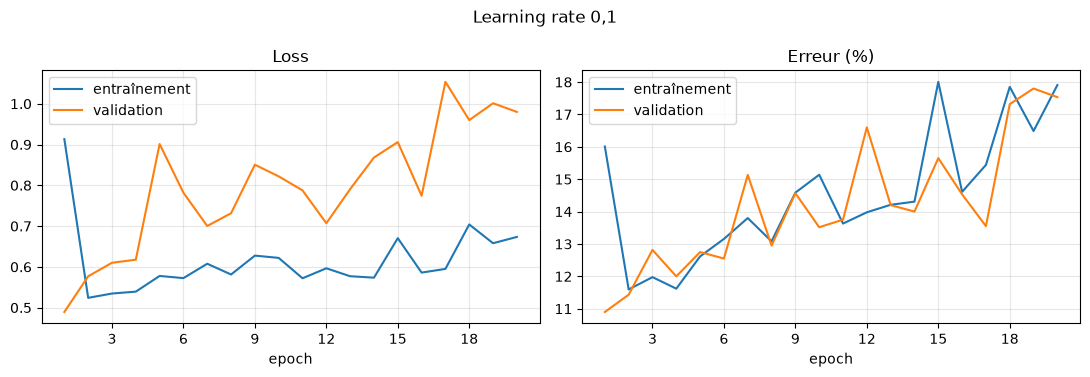

In [16]:
# Learning rate TROP ÉLEVÉ : 100 fois plus grand que la référence
model_lr_01, hist_lr_01 = run(
    "Learning rate 0,1",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.Adam(learning_rate=0.1),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="learning rate : 0,1 au lieu de 1e-3 (trop élevé)",
    save="../images/p2_lr_0.1.png",
)

Epoch 1/20


422/422 - 2s - 6ms/step - accuracy: 0.1891 - loss: 22.4630 - val_accuracy: 0.1408 - val_loss: 2.2462


Epoch 2/20


422/422 - 2s - 4ms/step - accuracy: 0.1440 - loss: 2.3535 - val_accuracy: 0.1195 - val_loss: 2.2784


Epoch 3/20


422/422 - 1s - 3ms/step - accuracy: 0.1193 - loss: 2.3259 - val_accuracy: 0.1225 - val_loss: 2.2709


... (30 outputs left out)

Epoch 19/20


422/422 - 2s - 4ms/step - accuracy: 0.1028 - loss: 2.3457 - val_accuracy: 0.1022 - val_loss: 2.3147


Epoch 20/20


422/422 - 2s - 4ms/step - accuracy: 0.1028 - loss: 2.3457 - val_accuracy: 0.1022 - val_loss: 2.3147


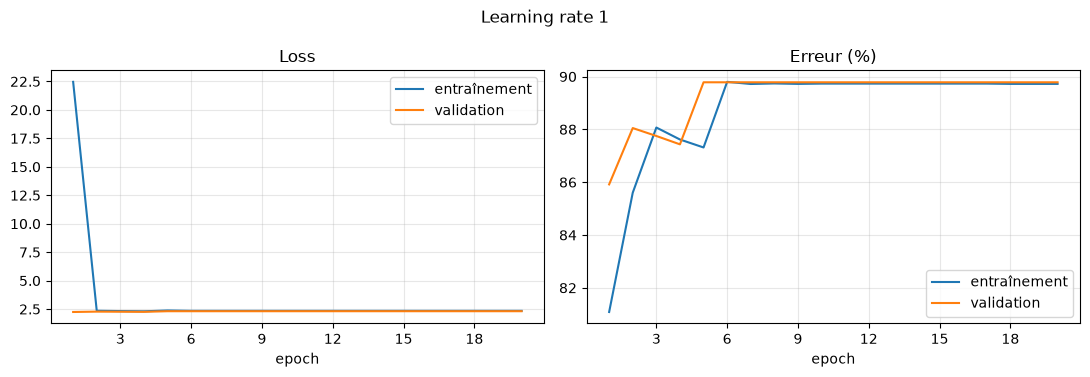

In [17]:
# Learning rate ÉNORME : 1 000 fois plus grand que la référence
model_lr_1, hist_lr_1 = run(
    "Learning rate 1",
    creer_modele=lambda: build_mlp(hidden=(256,)),
    optimizer=keras.optimizers.Adam(learning_rate=1.0),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=20,
    changement="learning rate : 1 au lieu de 1e-3 (beaucoup trop élevé)",
    save="../images/p2_lr_1.png",
)

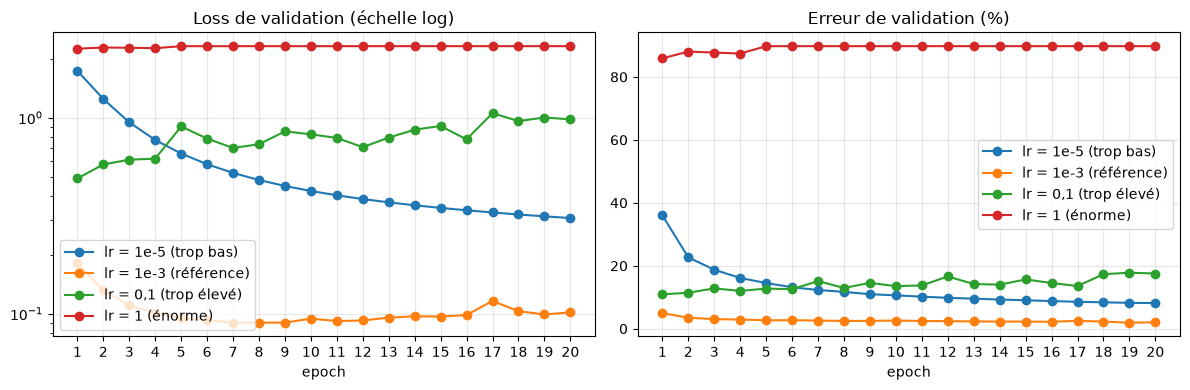

lr = 1e-5 (trop bas)     loss val : epoch 1 = 1.732, epoch 20 = 0.307 | erreur val : epoch 1 = 36.00 %, epoch 20 = 8.15 % | nan : False
lr = 1e-3 (référence)    loss val : epoch 1 = 0.181, epoch 20 = 0.102 | erreur val : epoch 1 = 4.95 %, epoch 20 = 2.03 % | nan : False
lr = 0,1 (trop élevé)    loss val : epoch 1 = 0.489, epoch 20 = 0.980 | erreur val : epoch 1 = 10.90 %, epoch 20 = 17.53 % | nan : False
lr = 1 (énorme)          loss val : epoch 1 = 2.246, epoch 20 = 2.315 | erreur val : epoch 1 = 85.92 %, epoch 20 = 89.78 % | nan : False


In [18]:
# Les learning rates superposés (la référence 1e-3 = hist_ref, déjà entraînée en section 3)
epochs = np.arange(1, 21)
courbes_lr = [(hist_lr_1e5, "lr = 1e-5 (trop bas)"),
              (hist_ref, "lr = 1e-3 (référence)"),
              (hist_lr_01, "lr = 0,1 (trop élevé)"),
              (hist_lr_1, "lr = 1 (énorme)")]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hist, nom in courbes_lr:
    axes[0].plot(epochs, hist.history["val_loss"], marker="o", label=nom)
    axes[1].plot(epochs, erreur_val(hist), marker="o", label=nom)
axes[0].set_title("Loss de validation (échelle log)")
axes[0].set_yscale("log")
axes[1].set_title("Erreur de validation (%)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_xticks(epochs)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("../images/p2_learning_rates.png", dpi=100, bbox_inches="tight")
plt.show()

for hist, nom in courbes_lr:
    vl = np.array(hist.history["val_loss"])
    print(f"{nom:24s} loss val : epoch 1 = {vl[0]:.3f}, epoch 20 = {vl[-1]:.3f}"
          f" | erreur val : epoch 1 = {erreur_val(hist)[0]:.2f} %, epoch 20 = {erreur_val(hist)[-1]:.2f} %"
          f" | nan : {np.isnan(vl).any()}")

**Ce que montrent les courbes** (`images/p2_learning_rates.png`) :

- **lr = 1e-5 (trop bas)** : la loss de validation descend, mais **très lentement et régulièrement**, comme une tortue. Elle passe de 1,73 à l'epoch 1 à 0,31 à l'epoch 20, alors que la référence est déjà à 0,18 après une seule epoch. L'erreur de validation est de 36 % après l'epoch 1 et de **8,15 % après 20 epochs** (contre 2,03 % pour la référence). Le modèle n'a pas « raté » : il n'a juste pas eu le temps d'arriver. La courbe descend encore.
- **lr = 0,1 (trop élevé)** : la loss de validation est au plus bas **dès l'epoch 1** (0,49), puis elle **remonte et zigzague** (0,98 à l'epoch 20). Les pas sont si grands que le modèle saute par-dessus le bon réglage au lieu de s'en approcher. L'erreur de validation passe de 10,9 % à **17,5 %** : le modèle se dégrade en apprenant.
- **lr = 1 (énorme)** : le modèle **n'apprend rien**. La loss de validation reste autour de 2,3, ce qui correspond à ln(10) ≈ 2,30, la loss d'un modèle qui répond au hasard parmi 10 classes. L'erreur est de **89,8 %**, soit à peu près 1 bonne réponse sur 10. Ici, la loss n'est pas devenue `nan` : probablement parce que les neurones se sont « bloqués » (des ReLU qui sortent toujours 0), et le modèle répond presque toujours la même chose.

➡️ **1e-3 (la valeur par défaut d'Adam) est de loin le meilleur des quatre**, et c'est le seul qui donne une courbe qui descend vite puis se stabilise.

## 6. Surapprentissage et sa correction

Pour **provoquer** le surapprentissage, je prends un modèle beaucoup plus gros que la référence : **3 couches cachées de 512 neurones** (932 362 paramètres, contre 203 530). Je l'entraîne **50 epochs**, sans aucune régularisation. J'utilise **toutes les 54 000 images** d'entraînement : j'ai vérifié avant que l'écart se voyait déjà bien, donc je n'ai pas eu besoin de réduire à 5 000 images.

Epoch 1/50


422/422 - 8s - 18ms/step - accuracy: 0.9320 - loss: 0.2226 - val_accuracy: 0.9643 - val_loss: 0.1178


Epoch 2/50


422/422 - 6s - 15ms/step - accuracy: 0.9745 - loss: 0.0831 - val_accuracy: 0.9707 - val_loss: 0.1066


Epoch 3/50


422/422 - 6s - 15ms/step - accuracy: 0.9828 - loss: 0.0542 - val_accuracy: 0.9748 - val_loss: 0.1003


... (90 outputs left out)

Epoch 49/50


422/422 - 6s - 15ms/step - accuracy: 0.9991 - loss: 0.0030 - val_accuracy: 0.9818 - val_loss: 0.1715


Epoch 50/50


422/422 - 6s - 14ms/step - accuracy: 0.9986 - loss: 0.0051 - val_accuracy: 0.9787 - val_loss: 0.1773


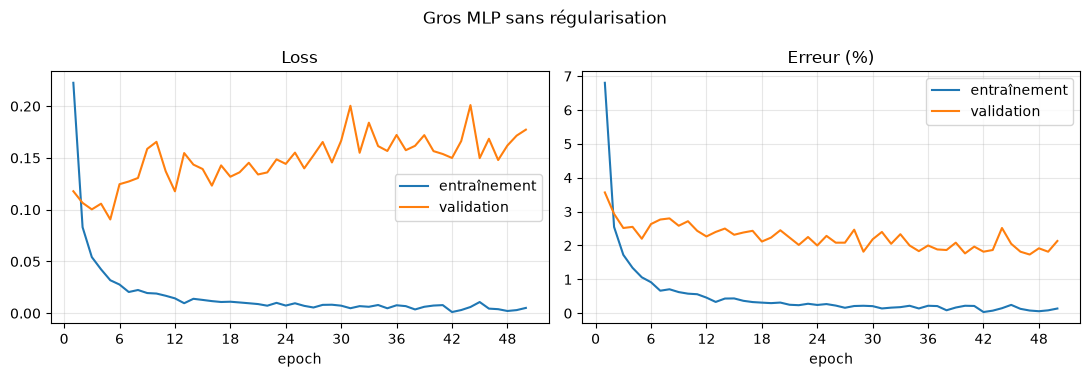

In [19]:
# Un modèle volontairement trop gros, entraîné longtemps, sans rien pour le freiner
model_gros, hist_gros = run(
    "Gros MLP sans régularisation",
    creer_modele=lambda: build_mlp(hidden=(512, 512, 512)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=50,
    changement="3 couches de 512, 50 epochs, aucune régularisation",
    save="../images/p2_gros_mlp_50ep.png",
)

In [20]:
vl_gros = np.array(hist_gros.history["val_loss"])
ep_min = int(vl_gros.argmin()) + 1
print(f"Loss de validation minimale : {vl_gros.min():.3f} à l'epoch {ep_min}, puis {vl_gros[-1]:.3f} à l'epoch 50")
print(f"Erreur d'entraînement finale : {100 * (1 - hist_gros.history['accuracy'][-1]):.2f} %"
      f" | erreur de validation finale : {erreur_val(hist_gros)[-1]:.2f} %"
      f" (meilleure : {erreur_val(hist_gros).min():.2f} % à l'epoch {erreur_val(hist_gros).argmin() + 1})")

Loss de validation minimale : 0.091 à l'epoch 5, puis 0.177 à l'epoch 50
Erreur d'entraînement finale : 0.14 % | erreur de validation finale : 2.13 % (meilleure : 1.73 % à l'epoch 47)


**Le moment où le modèle commence à apprendre par cœur : l'epoch 5.** C'est là que la loss de validation est la plus basse (**0,091**). Ensuite, elle remonte presque sans arrêt, jusqu'à **0,177 à l'epoch 50** (presque le double). Pendant ce temps, l'erreur d'entraînement tombe à **0,14 %** : le modèle connaît les images d'entraînement par cœur, mais il devient de plus en plus « sûr de lui » sur les images de validation qu'il classe mal. C'est la ligne rouge en pointillés sur le graphique plus bas.

Remarque : l'erreur de validation, elle, ne remonte pas vraiment (elle oscille entre 1,7 et 2,5 % et finit à 2,13 %). C'est surtout la **loss** qui montre le surapprentissage.

Epoch 1/50


422/422 - 7s - 17ms/step - accuracy: 0.9320 - loss: 0.2226 - val_accuracy: 0.9643 - val_loss: 0.1178


Epoch 2/50


422/422 - 6s - 14ms/step - accuracy: 0.9745 - loss: 0.0831 - val_accuracy: 0.9707 - val_loss: 0.1066


Epoch 3/50


422/422 - 6s - 14ms/step - accuracy: 0.9828 - loss: 0.0542 - val_accuracy: 0.9748 - val_loss: 0.1003


... (10 outputs left out)

Epoch 9/50


422/422 - 6s - 14ms/step - accuracy: 0.9938 - loss: 0.0195 - val_accuracy: 0.9742 - val_loss: 0.1587


Epoch 10/50


422/422 - 6s - 14ms/step - accuracy: 0.9942 - loss: 0.0190 - val_accuracy: 0.9728 - val_loss: 0.1655


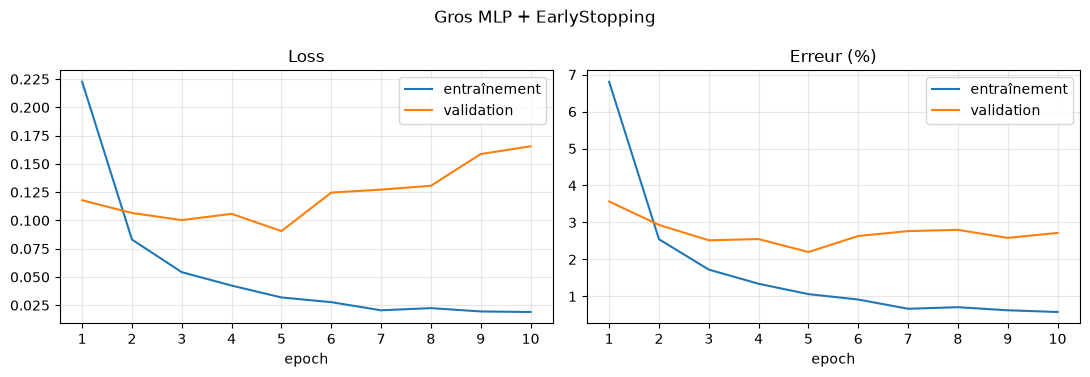

In [21]:
# Correction 1 : on arrête quand la loss de validation ne s'améliore plus depuis 5 epochs,
# et on revient aux poids de la meilleure epoch
model_es, hist_es = run(
    "Gros MLP + EarlyStopping",
    creer_modele=lambda: build_mlp(hidden=(512, 512, 512)),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=50,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
    changement="même gros MLP + EarlyStopping(val_loss, patience 5, meilleurs poids)",
    save="../images/p2_gros_mlp_earlystopping.png",
)

In [22]:
n_ep = len(hist_es.history["val_loss"])
meilleure = int(np.argmin(hist_es.history["val_loss"])) + 1
print(f"Arrêt à l'epoch {n_ep} (meilleure loss de validation à l'epoch {meilleure}, + 5 epochs de patience)")
print(f"Erreur de validation des poids restaurés : {resultats[-1]['erreur_val_%']:.2f} %")

Arrêt à l'epoch 10 (meilleure loss de validation à l'epoch 5, + 5 epochs de patience)
Erreur de validation des poids restaurés : 2.20 %


Epoch 1/50


422/422 - 8s - 18ms/step - accuracy: 0.9071 - loss: 0.3035 - val_accuracy: 0.9610 - val_loss: 0.1324


Epoch 2/50


422/422 - 7s - 15ms/step - accuracy: 0.9606 - loss: 0.1346 - val_accuracy: 0.9660 - val_loss: 0.1200


Epoch 3/50


422/422 - 7s - 15ms/step - accuracy: 0.9701 - loss: 0.0986 - val_accuracy: 0.9703 - val_loss: 0.0993


... (90 outputs left out)

Epoch 49/50


422/422 - 7s - 17ms/step - accuracy: 0.9951 - loss: 0.0174 - val_accuracy: 0.9817 - val_loss: 0.1033


Epoch 50/50


422/422 - 11s - 25ms/step - accuracy: 0.9956 - loss: 0.0154 - val_accuracy: 0.9803 - val_loss: 0.1213


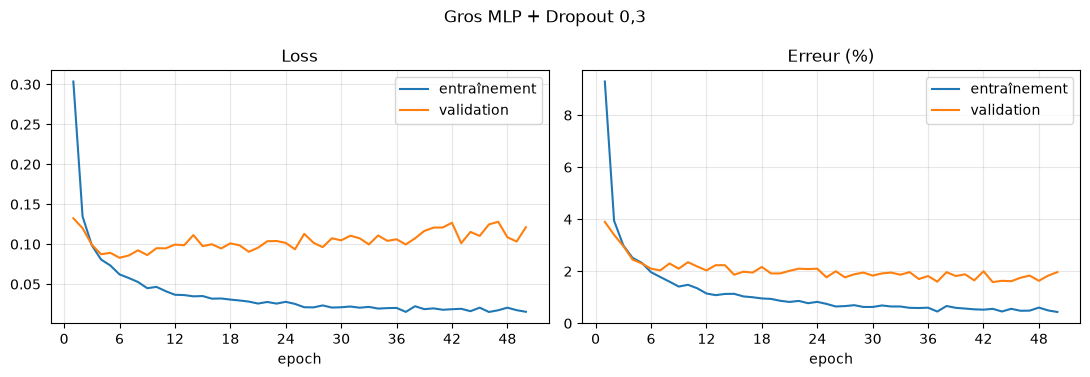

In [23]:
# Correction 2 : Dropout 0,3 -> à chaque itération, 30 % des neurones cachés sont éteints au hasard
model_dropout, hist_dropout = run(
    "Gros MLP + Dropout 0,3",
    creer_modele=lambda: build_mlp(hidden=(512, 512, 512), dropout=0.3),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    donnees=donnees,
    resultats=resultats,
    batch_size=128,
    epochs=50,
    changement="même gros MLP + Dropout(0,3) après chaque couche cachée, 50 epochs",
    save="../images/p2_gros_mlp_dropout.png",
)

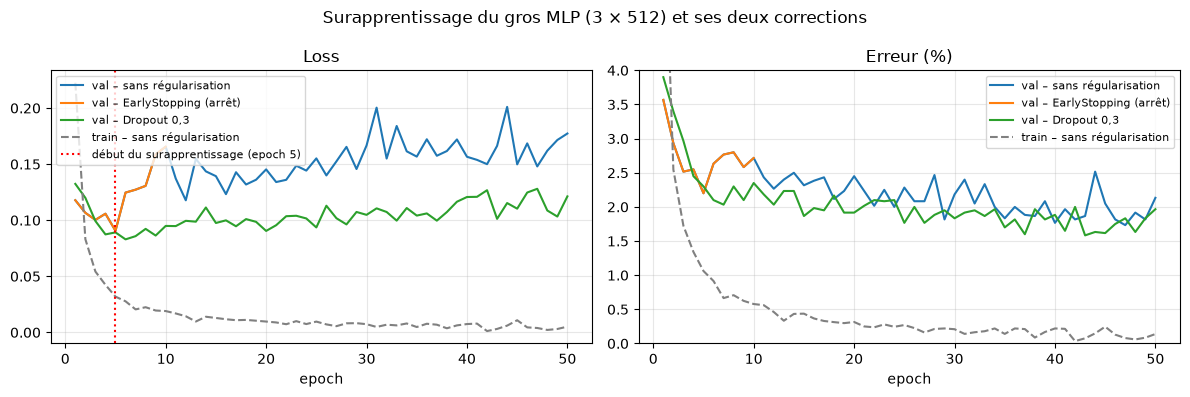

In [24]:
# Avant / après : gros MLP sans régularisation, avec EarlyStopping, avec Dropout
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hist, nom, style in [(hist_gros, "sans régularisation", "-"),
                         (hist_es, "EarlyStopping (arrêt)", "-"),
                         (hist_dropout, "Dropout 0,3", "-")]:
    ep = np.arange(1, len(hist.history["val_loss"]) + 1)
    axes[0].plot(ep, hist.history["val_loss"], style, label=f"val – {nom}")
    axes[1].plot(ep, erreur_val(hist), style, label=f"val – {nom}")
# l'entraînement du modèle sans régularisation, en pointillés, pour voir l'écart
ep50 = np.arange(1, 51)
axes[0].plot(ep50, hist_gros.history["loss"], "--", color="gray", label="train – sans régularisation")
axes[1].plot(ep50, 100 * (1 - np.array(hist_gros.history["accuracy"])), "--", color="gray",
             label="train – sans régularisation")
axes[0].axvline(ep_min, color="red", linestyle=":", label=f"début du surapprentissage (epoch {ep_min})")
axes[0].set_title("Loss")
axes[1].set_title("Erreur (%)")
axes[1].set_ylim(0, 4)
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("Surapprentissage du gros MLP (3 × 512) et ses deux corrections")
plt.tight_layout()
plt.savefig("../images/p2_surapprentissage.png", dpi=100, bbox_inches="tight")
plt.show()

In [25]:
# Le modèle avec Dropout : erreur d'entraînement contre erreur de validation à la fin
err_train_do = 100 * (1 - hist_dropout.history["accuracy"][-1])
print(f"Dropout, epoch 50 : erreur train = {err_train_do:.2f} %, erreur val = {erreur_val(hist_dropout)[-1]:.2f} %")
print(f"Dropout, loss val : min {min(hist_dropout.history['val_loss']):.3f}, finale {hist_dropout.history['val_loss'][-1]:.3f}")

pd.DataFrame(resultats).sort_values("erreur_val_%").reset_index(drop=True)

Dropout, epoch 50 : erreur train = 0.44 %, erreur val = 1.97 %
Dropout, loss val : min 0.083, finale 0.121


,nom,changement,parametres,epochs,erreur_val_%,meilleure_erreur_val_%,epoch_meilleure,duree_s
0,Largeur 512,largeur : 512 neurones au lieu de 256,407050,20,1.80,1.80,20,67.3
1,"Gros MLP + Dropout 0,3","même gros MLP + Dropout(0,3) après chaque couc...",932362,50,1.97,1.58,43,366.0
2,MLP de référence,"référence : 256 neurones, Adam 1e-3, batch 128",203530,20,2.03,1.92,19,33.5
3,Gros MLP sans régularisation,"3 couches de 512, 50 epochs, aucune régularisa...",932362,50,2.13,1.73,47,306.6
4,Gros MLP + EarlyStopping,"même gros MLP + EarlyStopping(val_loss, patien...",932362,10,2.20,2.20,5,60.2
5,Profondeur 256 → 128,profondeur : 2 couches cachées (256 → 128),235146,20,2.25,2.10,15,35.6
6,Batch 512,batch size : 512 au lieu de 128,203530,20,2.37,2.32,19,17.0
7,Batch 32,batch size : 32 au lieu de 128,203530,20,2.37,2.13,15,103.7
8,"SGD lr 0,01","optimiseur : SGD (lr 0,01) au lieu d'Adam (lr ...",203530,20,6.52,6.52,20,28.1
9,Learning rate 1e-5,learning rate : 1e-5 au lieu de 1e-3 (trop bas),203530,20,8.15,8.15,20,32.6


**Bilan des deux corrections** (`images/p2_surapprentissage.png`) :

- **EarlyStopping** (sur `val_loss`, patience 5) : l'entraînement s'arrête **à l'epoch 10**. La meilleure loss de validation est à l'epoch 5, plus 5 epochs de patience, et les poids de l'epoch 5 sont restaurés. Durée : environ 60 s au lieu d'environ 300 s. L'erreur de validation des poids restaurés est de **2,20 %**. Il évite bien la remontée de la loss et fait gagner beaucoup de temps. Mais ici, il s'arrête un peu tôt : sans régularisation, l'erreur continuait à baisser lentement (1,73 % au mieux, à l'epoch 47), même si la loss remontait. Le critère `val_loss` est « prudent ».
- **Dropout 0,3** : la loss de validation monte **beaucoup moins** (minimum 0,083, puis 0,121 à la fin, contre 0,177 sans régularisation). L'erreur de validation finit à **1,97 %**, avec **1,58 % au mieux (epoch 43)**, la meilleure valeur de tous mes essais. Le modèle a moins « appris par cœur » : son erreur d'entraînement est de 0,44 % au lieu de 0,14 %. Mais c'est plus long (environ 6 min).
- **Pourquoi la validation est meilleure que l'entraînement au début avec Dropout** (epoch 1 : 3,9 % d'erreur en validation contre 9,3 % en entraînement) : c'est **normal**. Pendant l'entraînement, Keras éteint au hasard 30 % des neurones, et le modèle travaille donc « handicapé ». L'accuracy d'entraînement est mesurée dans ces conditions. Pour la validation, tous les neurones sont allumés, donc le modèle est meilleur.

Le tableau ci-dessus contient maintenant toutes les lignes, avec, pour l'EarlyStopping, l'erreur des poids restaurés (et pas celle de la dernière epoch). Je choisirai le meilleur modèle à la section 8, après la batch normalization.

## 7. Batch normalization : avec et sans

## 8. Tableau récapitulatif et choix du meilleur modèle (sur la validation)

## 9. Évaluation finale sur le test (une seule fois)

## 10. Réponses aux questions d'explication

**Q1. Avec 54 000 images d'entraînement et un batch de 128, combien d'itérations par epoch ? Que changent epochs, itérations et batch size à ce que j'observe ?**

54 000 / 128 = 421,875, donc **422 itérations par epoch** : 421 paquets de 128 images et un dernier paquet de 112. Keras affiche bien `422/422`.

- Une **itération** = une correction des poids, calculée sur un paquet d'images.
- Une **epoch** = un passage sur les 54 000 images.
- La **taille de batch** fixe le nombre d'itérations par epoch : 1 688 avec un batch de 32, 422 avec 128, et 106 avec 512.

Ce que je vois sur mes essais (`images/p2_batch_sizes.png`) :

- Avec un **petit batch (32)**, le modèle fait 4 fois plus de corrections par epoch. Il apprend donc plus vite *par epoch* : 4,3 % d'erreur après l'epoch 1, contre 5,0 % avec 128 et 7,2 % avec 512. Mais chaque epoch est plus longue (environ 6 s contre environ 1,5 s), et la courbe est plus « bruitée », parce que chaque correction est calculée sur peu d'images. Au total : environ 110 à 130 s, pour 2,37 % d'erreur.
- Avec un **gros batch (512)**, il y a seulement 106 corrections par epoch. Elles sont plus stables, mais il en faut plus d'epochs pour arriver au même niveau. C'est le plus rapide (environ 17 à 20 s), et il finit à 2,37 % d'erreur, comme le batch 32.
- Plus d'**epochs**, c'est plus de corrections. Sur la référence, l'erreur de validation baisse encore lentement jusqu'à l'epoch 20, mais la loss de validation remonte dès l'epoch 7 à 9 (début de surapprentissage). Ajouter des epochs n'aide donc plus beaucoup.

Au bout de 20 epochs, les trois tailles de batch arrivent au même niveau (entre 2,0 et 2,4 %). Ce qui change surtout, c'est **le temps** et **la vitesse de départ**.

**Q2. Montrez sur vos courbes les conséquences d'un learning rate trop bas et trop élevé.**

Même modèle que la référence (784 → 256 → 10, Adam, batch 128, 20 epochs, même graine). Seul le learning rate change (`images/p2_learning_rates.png`) :

| learning rate | loss val epoch 1 → 20 | erreur val epoch 1 → 20 |
|---|---|---|
| 1e-5 (trop bas) | 1,73 → 0,31 | 36,0 % → 8,15 % |
| **1e-3 (référence)** | **0,18 → 0,10** | **4,95 % → 2,03 %** |
| 0,1 (trop élevé) | 0,49 → 0,98 | 10,9 % → 17,5 % |
| 1 (énorme) | 2,25 → 2,32 | 85,9 % → 89,8 % |

- **Trop bas (1e-5)** : la courbe descend **très lentement mais régulièrement**. Après 20 epochs, le modèle est encore à 8 % d'erreur, l'équivalent de moins d'une epoch avec la référence. Le modèle n'est pas faux, il est **trop lent** : il faudrait des centaines d'epochs.
- **Trop élevé (0,1)** : la loss de validation est la meilleure dès l'epoch 1, puis elle **remonte en zigzag**, et l'erreur double (10,9 % → 17,5 %). Les corrections sont tellement grandes que le modèle saute de part et d'autre du minimum au lieu d'y descendre.
- **Énorme (1)** : le modèle **décroche complètement**. La loss reste à environ 2,30 = ln(10), c'est-à-dire « je réponds au hasard entre 10 chiffres », et l'erreur reste vers 90 %. Je n'ai pas eu de `nan`, mais le modèle reste bloqué et ne réapprend plus rien.

Le bon learning rate (1e-3) est celui qui fait descendre la loss **vite au début, puis la stabilise**.

**Q3. La Batch normalization a-t-elle aidé sur mon modèle ?**

*À compléter (jour 7, section 7).*

**Q4. Adam face à SGD : lequel converge le plus vite chez moi, et pourquoi, selon moi ?**

**Adam converge beaucoup plus vite.** Même modèle (784 → 256 → 10), même graine, même batch de 128, 20 epochs. Seul l'optimiseur change : Adam avec lr 0,001 (la valeur par défaut), contre SGD avec lr 0,01 (une valeur classique et raisonnable pour SGD). Voici l'erreur de validation (`images/p2_adam_vs_sgd.png`) :

| epoch | Adam | SGD |
|---|---|---|
| 1 | 4,95 % | 15,62 % |
| 5 | 2,67 % | 9,73 % |
| 10 | 2,60 % | 8,00 % |
| 20 | 2,03 % | 6,52 % |

Adam atteint en **une seule epoch** une erreur que SGD n'atteint toujours pas après 20 epochs. La durée est du même ordre (environ 25 à 35 s) : ce n'est pas plus lent par epoch, c'est juste que chaque pas d'Adam est plus « efficace ».

**Pourquoi, selon moi :** SGD fait des pas de **même taille** pour tous les poids, toujours dans la direction du gradient du paquet en cours. Si le pas est petit, il avance lentement. Adam, lui, adapte la taille du pas **pour chaque poids** : un poids dont le gradient est faible mais constant reçoit un pas plus grand. Il garde aussi une **moyenne des gradients précédents** (le « momentum »), ce qui lisse les directions et l'empêche de zigzaguer. Résultat : il descend la loss bien plus vite au début.

SGD n'est pas « mauvais » pour autant : sa courbe descend encore à l'epoch 20. Avec plus d'epochs, un lr plus grand ou du momentum, il finirait sûrement par se rapprocher d'Adam. Mais à budget égal (20 epochs), Adam gagne nettement.

## 11. Bilan du palier 2